# Data Cleaning & Feature Engineering

- Data cleaning (`age`=995)
- Target encoding (`geo_level_2_id`, `geo_level_3_id`)
- Handling rare categories in categorical features (`ground_floor_type`, `plan_configuration`, `legal_ownership_status`, `geo_level_1_id`)
- Feature creation (`has_secondary_use_*`, `height_area_ratio`)
- Dropping `building_id`
- Standardisation
- Log transformation
- One-hot encoding
- Handling class imbalance 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('../data/raw/train_values.csv')
target = pd.read_csv('../data/raw/train_labels.csv')
test_value = pd.read_csv('../data/raw/test_values.csv')

data.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Merge data and target into one DataFrame

df = pd.merge(data, target, on=['building_id'])
df.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


In [4]:
df1 = df.copy()
test_value1 = test_value.copy()

### Data Cleaning

Having a building age of 995 years is not reasonable and is considered an error.

In [5]:
df[df['age'] == 995]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
386,435557,14,1120,3789,3,995,12,5,t,r,...,0,0,0,0,0,0,0,0,0,2
716,597626,26,39,1851,2,995,27,6,t,i,...,0,0,0,0,0,0,0,0,0,1
1235,7560,26,1132,9472,2,995,8,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1398,797271,26,39,1851,2,995,14,6,t,u,...,0,0,0,0,0,0,0,0,0,1
1635,857371,24,628,10750,2,995,10,5,t,r,...,0,0,0,0,0,0,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259758,160373,27,390,11020,3,995,6,8,n,r,...,0,0,0,0,0,0,0,0,0,2
259893,9269,24,628,11511,2,995,8,5,n,r,...,0,0,0,0,0,0,0,0,0,2
260093,34321,17,1393,5939,2,995,8,4,t,r,...,0,0,0,0,0,0,0,0,0,3
260542,156434,8,696,7863,2,995,8,8,t,r,...,0,0,0,0,0,0,0,0,0,3


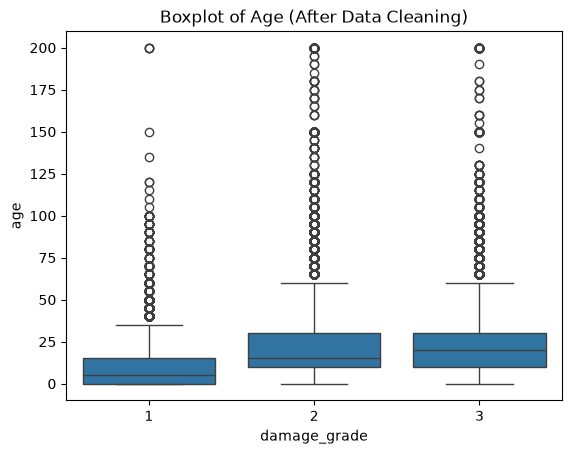

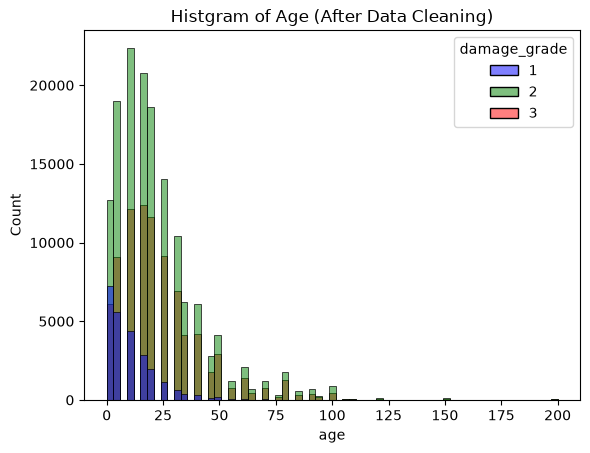

In [6]:
# Errors are replaced with null values and will be imputed later in the pipeline.

df1['age'] = df1['age'].where(df1['age'] <= 200, np.nan)

# Plot
sns.boxplot(data=df1, x='damage_grade', y='age')
plt.title('Boxplot of Age (After Data Cleaning)')
plt.show()

sns.histplot(data=df1, x='age', hue='damage_grade', palette=['blue', 'green', 'red'], binwidth=3)
plt.title('Histgram of Age (After Data Cleaning)')
plt.show()

In [7]:
# Apply the same preprocessing steps to test_values dataset

test_value1['age'] = test_value1['age'].where(test_value1['age'] <= 200, np.nan)

### Dropping `building_id`

In [8]:
df1.drop('building_id', axis=1, inplace=True)
df1

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,6,487,12198,2,30.0,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
1,8,900,2812,2,10.0,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,2
2,21,363,8973,2,10.0,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
3,22,418,10694,2,10.0,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,2
4,11,131,1488,3,30.0,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260596,25,1335,1621,1,55.0,6,3,n,r,n,...,0,0,0,0,0,0,0,0,0,2
260597,17,715,2060,2,0.0,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
260598,17,51,8163,3,55.0,6,7,t,r,q,...,0,0,0,0,0,0,0,0,0,3
260599,26,39,1851,2,10.0,14,6,t,r,x,...,0,0,0,0,0,0,0,0,0,2


In [9]:
# Apply the same preprocessing steps to test_values dataset
test_value1.drop('building_id', axis=1, inplace=True)
test_value1

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,17,596,11307,3,20.0,7,6,t,r,n,...,0,0,0,0,0,0,0,0,0,0
1,6,141,11987,2,25.0,13,5,t,r,n,...,1,0,0,0,0,0,0,0,0,0
2,22,19,10044,2,5.0,4,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
3,26,39,633,1,0.0,19,3,t,r,x,...,0,0,1,0,0,0,0,0,0,0
4,17,289,7970,3,15.0,8,7,t,r,q,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86863,4,605,3623,3,70.0,20,6,t,r,q,...,1,0,0,0,0,0,0,0,0,0
86864,10,1407,11907,3,25.0,6,7,n,r,n,...,0,0,0,0,0,0,0,0,0,0
86865,22,1136,7712,1,50.0,3,3,t,r,n,...,0,0,0,0,0,0,0,0,0,0
86866,6,1041,912,2,5.0,9,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0


### Create a New Feature `height_area_ratio`

Since both `height_percentage` and `area_percentage` are normalised values, it is reasonable to create a height/area ratio feature.  
The ratio can reflect the structural form of the building and may be related to its earthquake resistance. Additionally, it might reduce the high correlation between `height_percentage` and `count_floors_pre_eq`.  

In [10]:
# Correlation between 'count_floors_pre_eq' and 'height_percentage'
df1['count_floors_pre_eq'].corr(df1['height_percentage'])

np.float64(0.7727343845138257)

In [11]:
# Height divided by area

df1['height_area_ratio'] = df1['height_percentage'] / df1['area_percentage']
df1[['height_area_ratio', 'height_percentage', 'area_percentage']]

,height_area_ratio,height_percentage,area_percentage
0,0.833333,5,6
1,0.875000,7,8
2,1.000000,5,5
3,0.833333,5,6
4,1.125000,9,8
...,...,...,...
260596,0.500000,3,6
260597,0.833333,5,6
260598,1.166667,7,6
260599,0.428571,6,14


In [12]:
# Correlation between the target and the new feature 'height_area_ratio'
df1['damage_grade'].corr(df1['height_area_ratio'])

np.float64(0.10878676704410031)

In [13]:
# Correlation between 'count_floors_pre_eq' and the new feature 'height_area_ratio'
df1['count_floors_pre_eq'].corr(df1['height_area_ratio'])

np.float64(0.3456474552842878)

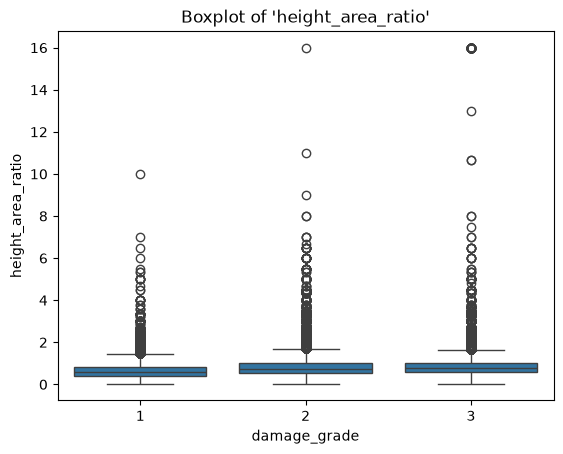

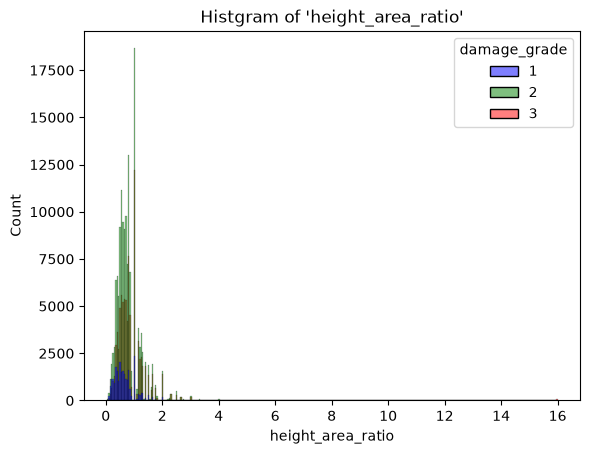

In [14]:
# Plot

sns.boxplot(data=df1, x='damage_grade', y='height_area_ratio')
plt.title("Boxplot of 'height_area_ratio'")
plt.show()

sns.histplot(data=df1, x='height_area_ratio', hue='damage_grade', palette=['blue', 'green', 'red'], binwidth=0.05)
plt.title("Histgram of 'height_area_ratio'")
plt.show()

In [15]:
# Drop original columns
df1.drop(['height_percentage', 'area_percentage'], axis=1, inplace=True)

In [16]:
# Apply the same preprocessing steps to test_values dataset

test_value1['height_area_ratio'] = test_value1['height_percentage'] / test_value1['area_percentage']
test_value1.drop(['height_percentage', 'area_percentage'], axis=1, inplace=True)

### Recategorise Secondary-Use Features

Based on the data exploration results, `has_secondary_use` needs to be dropped.  
Since the secondary-use features, except for `has_secondary_use_other`, are mutually exclusive, they are categorised into three broader groups.

In [17]:
secondary_use_col = ['has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel',
       'has_secondary_use_rental', 'has_secondary_use_institution',
       'has_secondary_use_school', 'has_secondary_use_industry',
       'has_secondary_use_health_post', 'has_secondary_use_gov_office',
       'has_secondary_use_use_police', 'has_secondary_use_other']

In [18]:
# Secondary-use features are grouped into three categories: manufacture, public, business

df1['has_secondary_use_manufacture'] = ((df1['has_secondary_use_agriculture'] == 1) | (df1['has_secondary_use_industry'] == 1)).astype(int)
df1['has_secondary_use_public'] = ((df1['has_secondary_use_institution'] == 1) | (df1['has_secondary_use_school'] == 1) | (df1['has_secondary_use_health_post'] == 1) | (df1['has_secondary_use_gov_office'] == 1) | (df1['has_secondary_use_use_police'] == 1)).astype(int)
df1['has_secondary_use_business'] = ((df1['has_secondary_use_hotel'] == 1) | (df1['has_secondary_use_rental'] == 1)).astype(int)

df1

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,...,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade,height_area_ratio,has_secondary_use_manufacture,has_secondary_use_public,has_secondary_use_business
0,6,487,12198,2,30.0,t,r,n,f,q,...,0,0,0,0,0,3,0.833333,0,0,0
1,8,900,2812,2,10.0,o,r,n,x,q,...,0,0,0,0,0,2,0.875000,0,0,0
2,21,363,8973,2,10.0,t,r,n,f,x,...,0,0,0,0,0,3,1.000000,0,0,0
3,22,418,10694,2,10.0,t,r,n,f,x,...,0,0,0,0,0,2,0.833333,0,0,0
4,11,131,1488,3,30.0,t,r,n,f,x,...,0,0,0,0,0,3,1.125000,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260596,25,1335,1621,1,55.0,n,r,n,f,j,...,0,0,0,0,0,2,0.500000,0,0,0
260597,17,715,2060,2,0.0,t,r,n,f,q,...,0,0,0,0,0,3,0.833333,0,0,0
260598,17,51,8163,3,55.0,t,r,q,f,q,...,0,0,0,0,0,3,1.166667,0,0,0
260599,26,39,1851,2,10.0,t,r,x,v,s,...,0,0,0,0,0,2,0.428571,0,0,0


In [19]:
secondary_use_col.remove('has_secondary_use_other')
print(secondary_use_col)

['has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police']


In [20]:
# Drop original secondary-use features except 'has_secondary_use_other'

df1.drop(secondary_use_col, axis=1, inplace=True)
df1

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,...,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use_other,damage_grade,height_area_ratio,has_secondary_use_manufacture,has_secondary_use_public,has_secondary_use_business
0,6,487,12198,2,30.0,t,r,n,f,q,...,0,0,v,1,0,3,0.833333,0,0,0
1,8,900,2812,2,10.0,o,r,n,x,q,...,0,0,v,1,0,2,0.875000,0,0,0
2,21,363,8973,2,10.0,t,r,n,f,x,...,0,0,v,1,0,3,1.000000,0,0,0
3,22,418,10694,2,10.0,t,r,n,f,x,...,0,0,v,1,0,2,0.833333,0,0,0
4,11,131,1488,3,30.0,t,r,n,f,x,...,0,0,v,1,0,3,1.125000,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260596,25,1335,1621,1,55.0,n,r,n,f,j,...,0,0,v,1,0,2,0.500000,0,0,0
260597,17,715,2060,2,0.0,t,r,n,f,q,...,0,0,v,1,0,3,0.833333,0,0,0
260598,17,51,8163,3,55.0,t,r,q,f,q,...,0,0,v,1,0,3,1.166667,0,0,0
260599,26,39,1851,2,10.0,t,r,x,v,s,...,0,0,v,1,0,2,0.428571,0,0,0


In [21]:
# Apply the same preprocessing steps to test_values dataset

test_value1['has_secondary_use_manufacture'] = ((test_value1['has_secondary_use_agriculture'] == 1) | (test_value1['has_secondary_use_industry'] == 1)).astype(int)
test_value1['has_secondary_use_public'] = ((test_value1['has_secondary_use_institution'] == 1) | (test_value1['has_secondary_use_school'] == 1) | (test_value1['has_secondary_use_health_post'] == 1) | (test_value1['has_secondary_use_gov_office'] == 1) | (test_value1['has_secondary_use_use_police'] == 1)).astype(int)
test_value1['has_secondary_use_business'] = ((test_value1['has_secondary_use_hotel'] == 1) | (test_value1['has_secondary_use_rental'] == 1)).astype(int)

test_value1.drop(secondary_use_col, axis=1, inplace=True)

test_value1

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,...,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use_other,height_area_ratio,has_secondary_use_manufacture,has_secondary_use_public,has_secondary_use_business
0,17,596,11307,3,20.0,t,r,n,f,q,...,0,0,0,v,1,0,0.857143,0,0,0
1,6,141,11987,2,25.0,t,r,n,f,q,...,0,0,0,v,1,0,0.384615,1,0,0
2,22,19,10044,2,5.0,t,r,n,f,q,...,0,0,0,v,1,0,1.250000,0,0,0
3,26,39,633,1,0.0,t,r,x,v,j,...,0,0,0,v,2,0,0.157895,0,0,1
4,17,289,7970,3,15.0,t,r,q,f,q,...,0,0,0,v,1,0,0.875000,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86863,4,605,3623,3,70.0,t,r,q,f,q,...,0,0,0,w,1,0,0.300000,1,0,0
86864,10,1407,11907,3,25.0,n,r,n,f,q,...,0,0,0,v,1,0,1.166667,0,0,0
86865,22,1136,7712,1,50.0,t,r,n,f,j,...,0,0,0,v,1,0,1.000000,0,0,0
86866,6,1041,912,2,5.0,t,r,n,f,q,...,0,0,0,a,1,0,0.555556,0,0,0


## Save processed data

In [22]:
# Save the processed datasets

df1.to_csv('../data/processed/train_data_processed.csv', index=False)
test_value1.to_csv('../data/processed/test_values_processed.csv', index=False)